In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as pl

import os
os.makedirs("output", exist_ok=True)

In [2]:
#styling
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
})

mpl.rcParams['figure.constrained_layout.use'] = True

# import data

In [3]:
target = 'TOI519'

df = pd.read_csv('data/TOI519_LC_MuSCAT_z-band.csv')
time = np.array(df['BJD'])
flux = np.array(df['Flux'])
err = np.array(df['Err'])

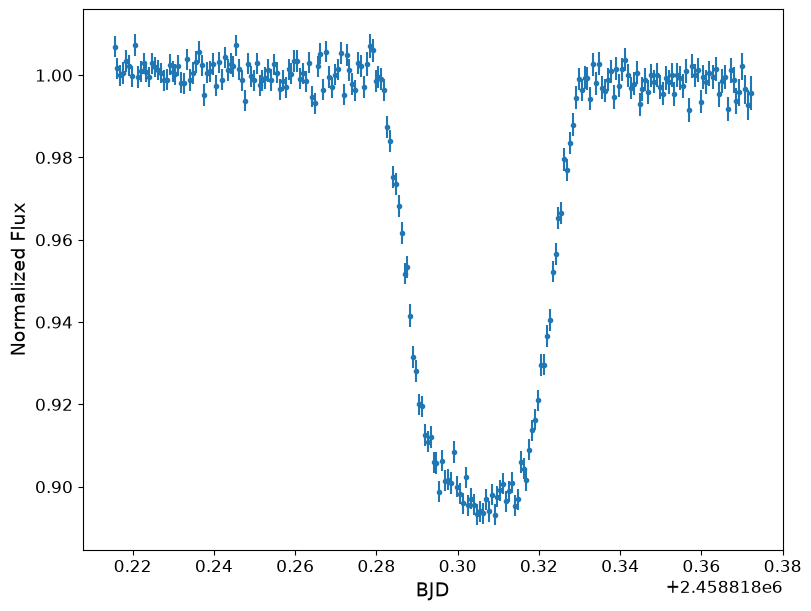

In [4]:
f = pl.figure(figsize=(8, 6))

pl.errorbar(time, flux, err, fmt='.')
pl.xlabel('BJD')
pl.ylabel('Normalized Flux')
f.savefig(f'output/{target}_transit_white.pdf')

# imput parameters

initial guess values from Parviainen et al. (2021)

In [5]:
T0_pr, T0_pr_e  = 2458491.8771169, 1.3e-4   #Transit center T0
P_pr, P_pr_e    = 1.2652328, 0.0000005      #Orbital Period

k_pr, k_pr_e = 0.3, 0.0091    #Rp/Rs
a_pr, a_pr_e = 10.11, 0.14    #a/Rs
b_pr, b_pr_e = 0.19, 0.06     #impact parameter, b

In [6]:
num = np.ceil((df['BJD'][0] - T0_pr)/P_pr) #Transit number from T0
Tc_pr = T0_pr + num * P_pr                 #Predicted Tc for this transit
Tc_pr_e = np.sqrt(T0_pr_e**2 + (num * P_pr_e)**2)
Tc_pr, Tc_pr_e

(np.float64(2458818.3071793), np.float64(0.00018314202139323458))

### limb darkening 

In [7]:
from ldtk import LDPSetCreator
from ldtk.filters import sdss_i

teff, uteff = 3324,  157
feh, ufeh   = 0.0,  0.7 
logg,ulogg = 4.86877, 0.000630214

In [8]:
sc = LDPSetCreator(teff=(teff,uteff), logg=(logg,ulogg), z=(feh,ufeh), filters=[sdss_i])
ps = sc.create_profiles(nsamples=2000)
ps.resample_linear_z(100)
qd_c,qd_e = ps.coeffs_qd(do_mc=True, n_mc_samples=10000)

In [9]:
u1_pr, u2_pr = list(qd_c[0])
#u1_pr_e, u2_pr_e = list(qd_e[0])

In [10]:
def u_to_q(u1, u2):
    q1 = (u1 + u2)**2
    q2 = u1 / (2 * (u1 + u2))
    return q1, q2

def q_to_u(q1, q2):
    u1 = 2 * np.sqrt(q1) * q2
    u2 = np.sqrt(q1) * (1 - 2*q2)
    return u1, u2

In [11]:
q1_pr, q2_pr = u_to_q(u1_pr, u2_pr)
q1_pr, q2_pr

(np.float64(0.6266274753919813), np.float64(0.3437038939639542))

# Transit Model

In [12]:
import batman
def transit_model(parameters, period, t):

    tc, a, b, k, q1, q2 = parameters
    
    inc= np.arccos(b/a)*180/np.pi
    u1, u2 = q_to_u(q1, q2)
    
    params = batman.TransitParams()
    params.t0 = tc         #time of inferior conjunction
    params.per = period    #orbital period
    params.rp = k          #planet radius (in units of stellar radii)
    params.a = a           #semi-major axis (in units of stellar radii)
    params.inc = inc       #orbital inclination (in degrees)
    params.ecc = 0.        #eccentricity
    params.w = 0.          #longitude of periastron (in degrees)
    params.u = [u1, u2]    #limb darkening coefficients [u1, u2]
    params.limb_dark = "quadratic" 

    m = batman.TransitModel(params, np.array(t))  
    
    return m.light_curve(params)

In [13]:
transit_params_init=[Tc_pr, a_pr, b_pr,k_pr, q1_pr, q2_pr]
transit_model_init=transit_model(transit_params_init, P_pr, time)

In [14]:
def plot_fit(time, flux, err, model, label, filename=None):
    resid = flux - model
    f, axs = pl.subplots(2, 1, figsize=(8, 8), height_ratios=(3,1), sharex=True)
    axs[0].errorbar(time, flux, err, fmt='.')
    axs[0].plot(time, model, label=label)
    axs[1].plot(time, resid, '.')
    axs[1].set_xlabel('BJD')
    axs[0].set_ylabel('Normalized Flux')
    axs[1].set_ylabel('Residual')
    axs[0].legend()
    if filename is not None:
        f.savefig(f'output/{target}_{filename}.pdf')

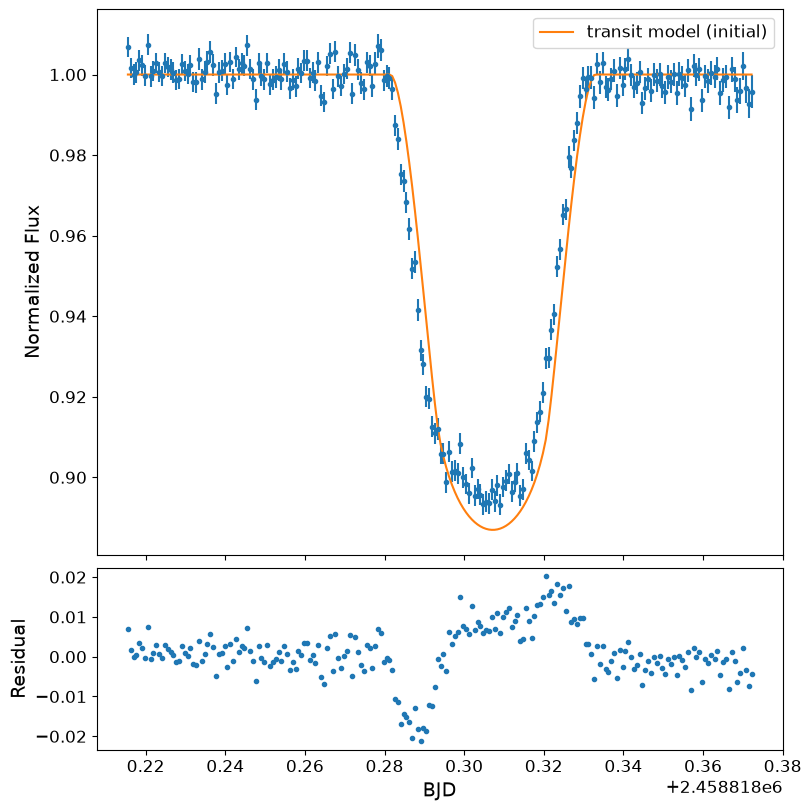

In [15]:
plot_fit(time, flux, err, transit_model_init, 
         'transit model (initial)','transit_initial')

# Simple baseline model 


In [16]:
def base_model(base_params, t):
    w0, w1, w2 = base_params
    x = t - t[0]
    return w0*np.ones_like(t) + w1*x + w2*x**2

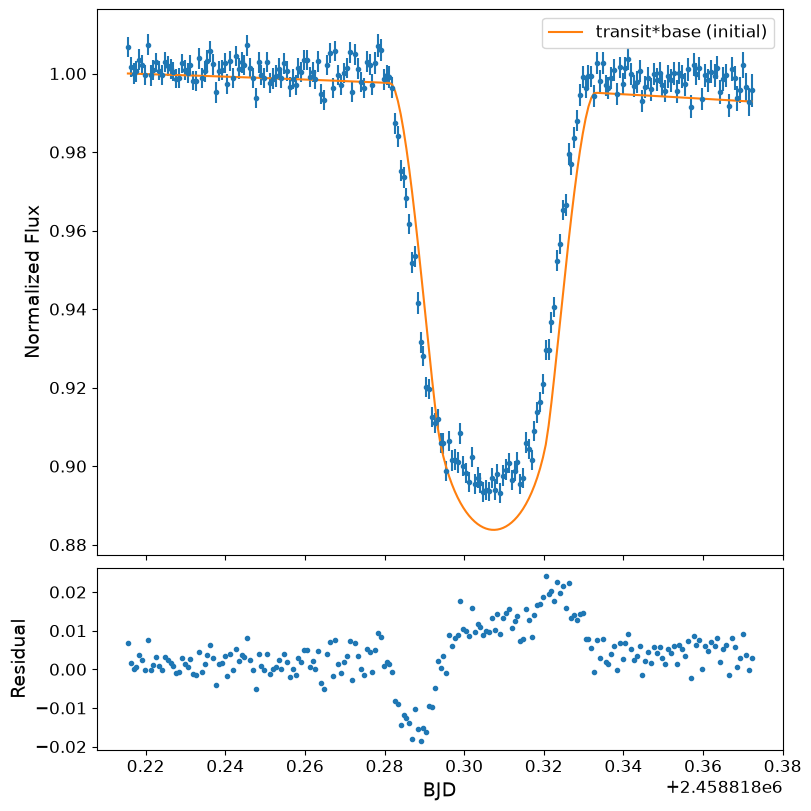

In [17]:
base_params_init = [1., -0.03, -0.1]
base_model_init = base_model(base_params_init,time)

plot_fit(time, flux, err, transit_model_init*base_model_init, 
         'transit*base (initial)','transit_base_initial')

# preparing parameter set

In [18]:
#transit_params_init=[Tc_pr,a_pr, b_pr,k_pr, q1_pr, q2_pr]
#base_params_init = [1., -0.05, -0.1]
params_full_init = transit_params_init + base_params_init
params_name = 'Tc,a_Rs,b,k,q1,q2,w0,w1,w2'.split(',')

In [19]:
len_t = len(transit_params_init)
len_b = len(base_params_init)

# preparing likelihood function

In [20]:
from scipy import stats

def logprior(params_full, time): #log-prior
    
    transit_params=params_full[:len_t]
    Tc, a, b, k, q1, q2 = transit_params
    
    base_params = params_full[len_t:]
    w0, w1, w2 = base_params
    
    #Uniform priors
    if not (time[0]<Tc<time[-1]):
        return -np.inf
    
    if not (1<a<100):
        return -np.inf
    
    if not all(0 < p <1 for p in [b, k, q1, q2]):
        return -np.inf
    
    #Normal Priors
    lp = 0
    
    lp += stats.norm.logpdf(a, loc=a_pr, scale=a_pr_e)
    lp += stats.norm.logpdf(b, loc=b_pr, scale=b_pr_e)
    
    #lp += stats.norm.logpdf(w0, loc=1.0, scale=0.1)
    #lp += stats.norm.logpdf(w1, loc=0.0, scale=0.1)
    #lp += stats.norm.logpdf(w2, loc=0.0, scale=0.1)
    
    return lp

def loglike(flux,err,model): #log-likelihood
    residual = flux - model
    return -0.5 * np.sum((residual/err)**2)

def logprob(params_full, time, flux, err):  #log-posterior probability

    lp = logprior(params_full, time)
    
    if not np.isfinite(lp):
        return -np.inf
    
    transit_params=params_full[:6]
    base_params=params_full[6:]
    
    tm = transit_model(transit_params, P_pr,time)
    sm = base_model(base_params,time)
    
    ll = loglike(flux, err, tm*sm)
    
    return ll+lp

In [21]:
logprob(params_full_init, time, flux, err)

np.float64(-1080.098204210303)

# Optimization

In [22]:
import scipy.optimize as op

def neg_logprob(params_full, time, flux, err):
    return -logprob(params_full, time, flux, err)

result = op.minimize(neg_logprob, params_full_init, 
                     args=(time, flux, err), method='Powell')

In [23]:
result.x

array([ 2.45881831e+06,  1.00374307e+01,  1.99584311e-01,  2.93571593e-01,
        4.34495960e-01,  3.45263755e-01,  1.00139877e+00, -1.54701809e-02,
       -5.48755349e-02])

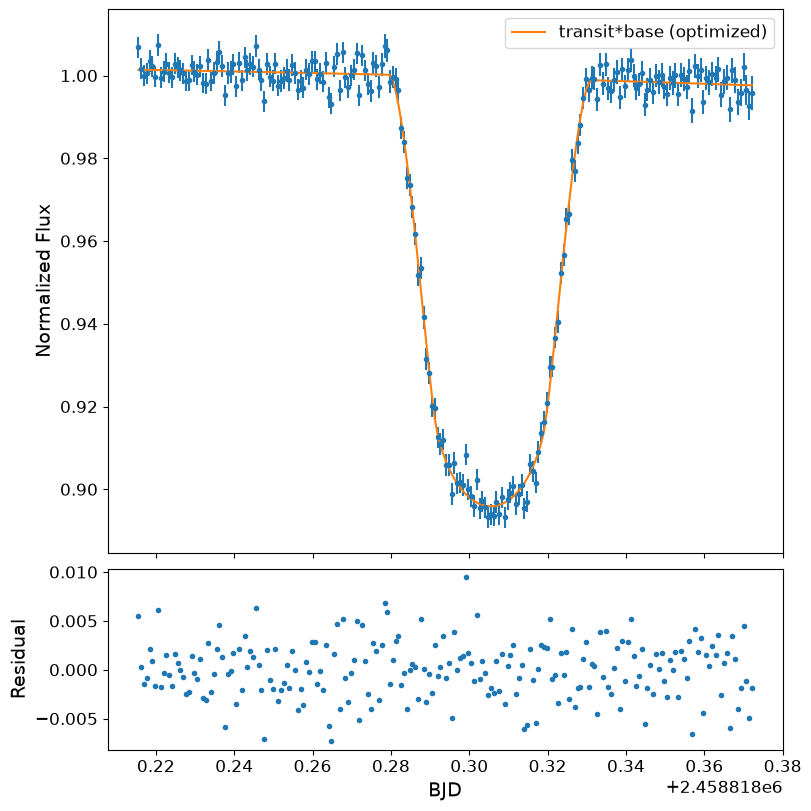

In [24]:
transit_params_opt=result.x[:len_t]
base_params_opt=result.x[len_t:]

transit_model_opt=transit_model(transit_params_opt, P_pr, time)
base_model_opt = base_model(base_params_opt,time)

plot_fit(time, flux, err, transit_model_opt*base_model_opt, 
         'transit*base (optimized)','transit_base_opt')

# MCMC

In [25]:
import emcee

params  = result.x
ndim = len(params)
nwalkers = 64
nsteps = 30000

In [26]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, logprob, 
                                args=(time, flux, err))

p0 = [params +  1e-5 * np.random.randn(ndim) for i in range(nwalkers)]
sampler.run_mcmc(p0, nsteps, progress=True)
samples = sampler.get_chain(discard=0, thin=1)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30000/30000 [05:02<00:00, 99.28it/s]


## check convergence

In [28]:
print("Mean acceptance fraction: {0:.3f}".format(np.mean(sampler.acceptance_fraction)))
print("Mean autocorrelation time: {0:.3f} steps".format(np.mean(sampler.get_autocorr_time())))

Mean acceptance fraction: 0.330
Mean autocorrelation time: 282.005 steps


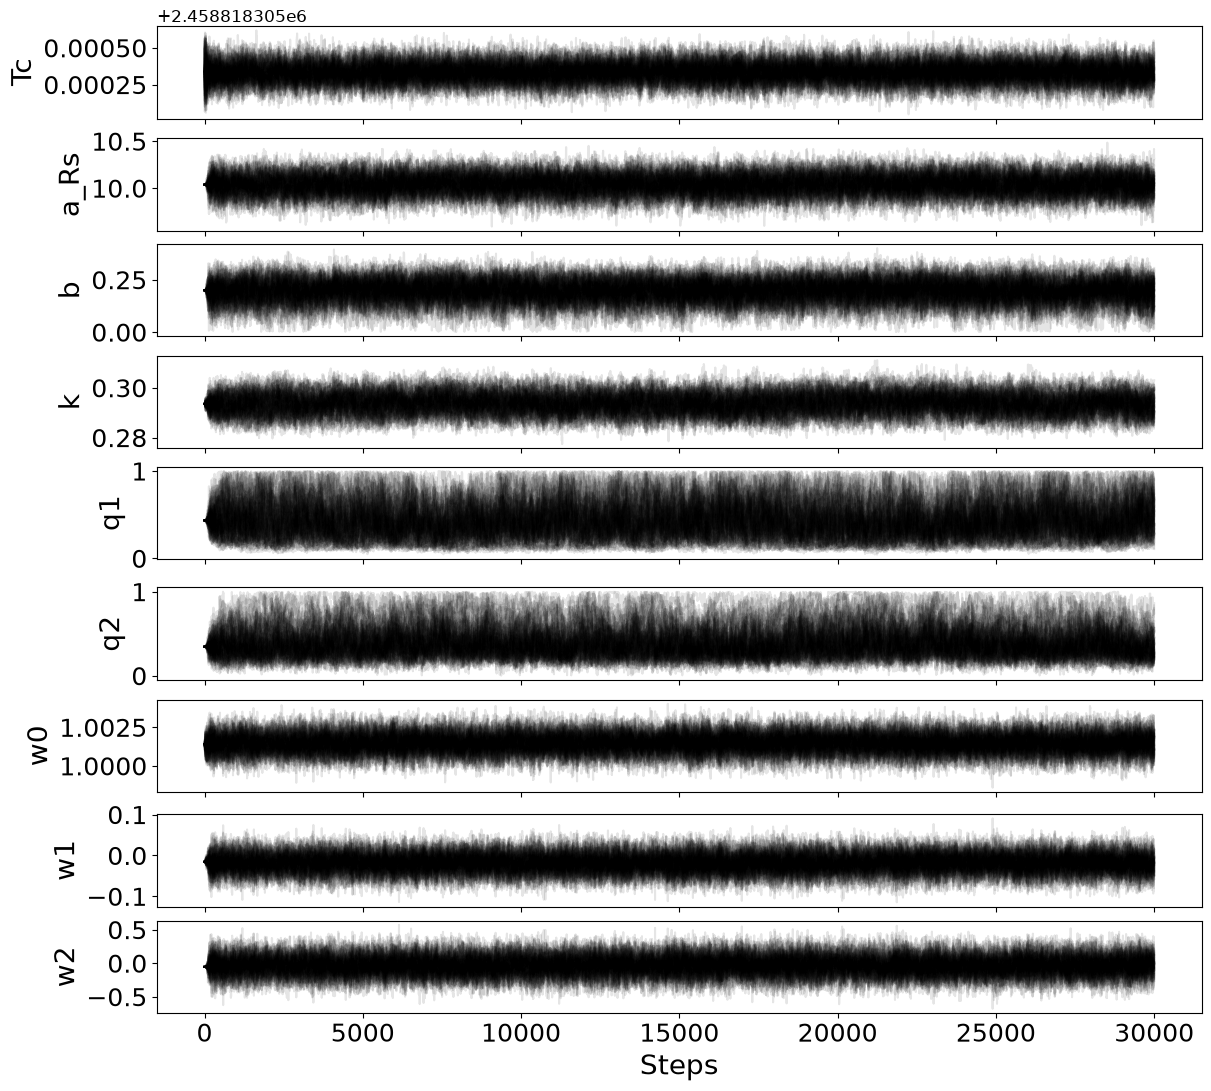

In [27]:
f, ax = pl.subplots(ndim, 1, figsize=(10*1.2,ndim*1.2))

for i in range(ndim):
    ax[i].plot(samples[:, :, i], color='k', alpha=0.1, rasterized=True)
    
    if i==(ndim-1):
        pl.setp(ax[i].get_xticklabels(), visible=True, fontsize=18)
        ax[i].set_xlabel('Steps', fontsize=20)
    else:
        pl.setp(ax[i].get_xticklabels(), visible=False)
    
    pl.setp(ax[i].get_yticklabels(), fontsize=18)
    ax[i].set_ylabel(params_name[i],fontsize=20)
    
f.savefig(f'output/{target}_chain.pdf')

# derive best parameters

In [29]:
flat_samples = sampler.get_chain(discard=15000, thin=10, flat=True)

In [30]:
params_full_best=[]
params_full_best_err = []

for i in range(ndim):
    mcmc = np.percentile(flat_samples[:, i], [16, 50, 84])
    q = np.diff(mcmc)

    params_full_best.append(mcmc[1])
    params_full_best_err.append(np.mean(q))

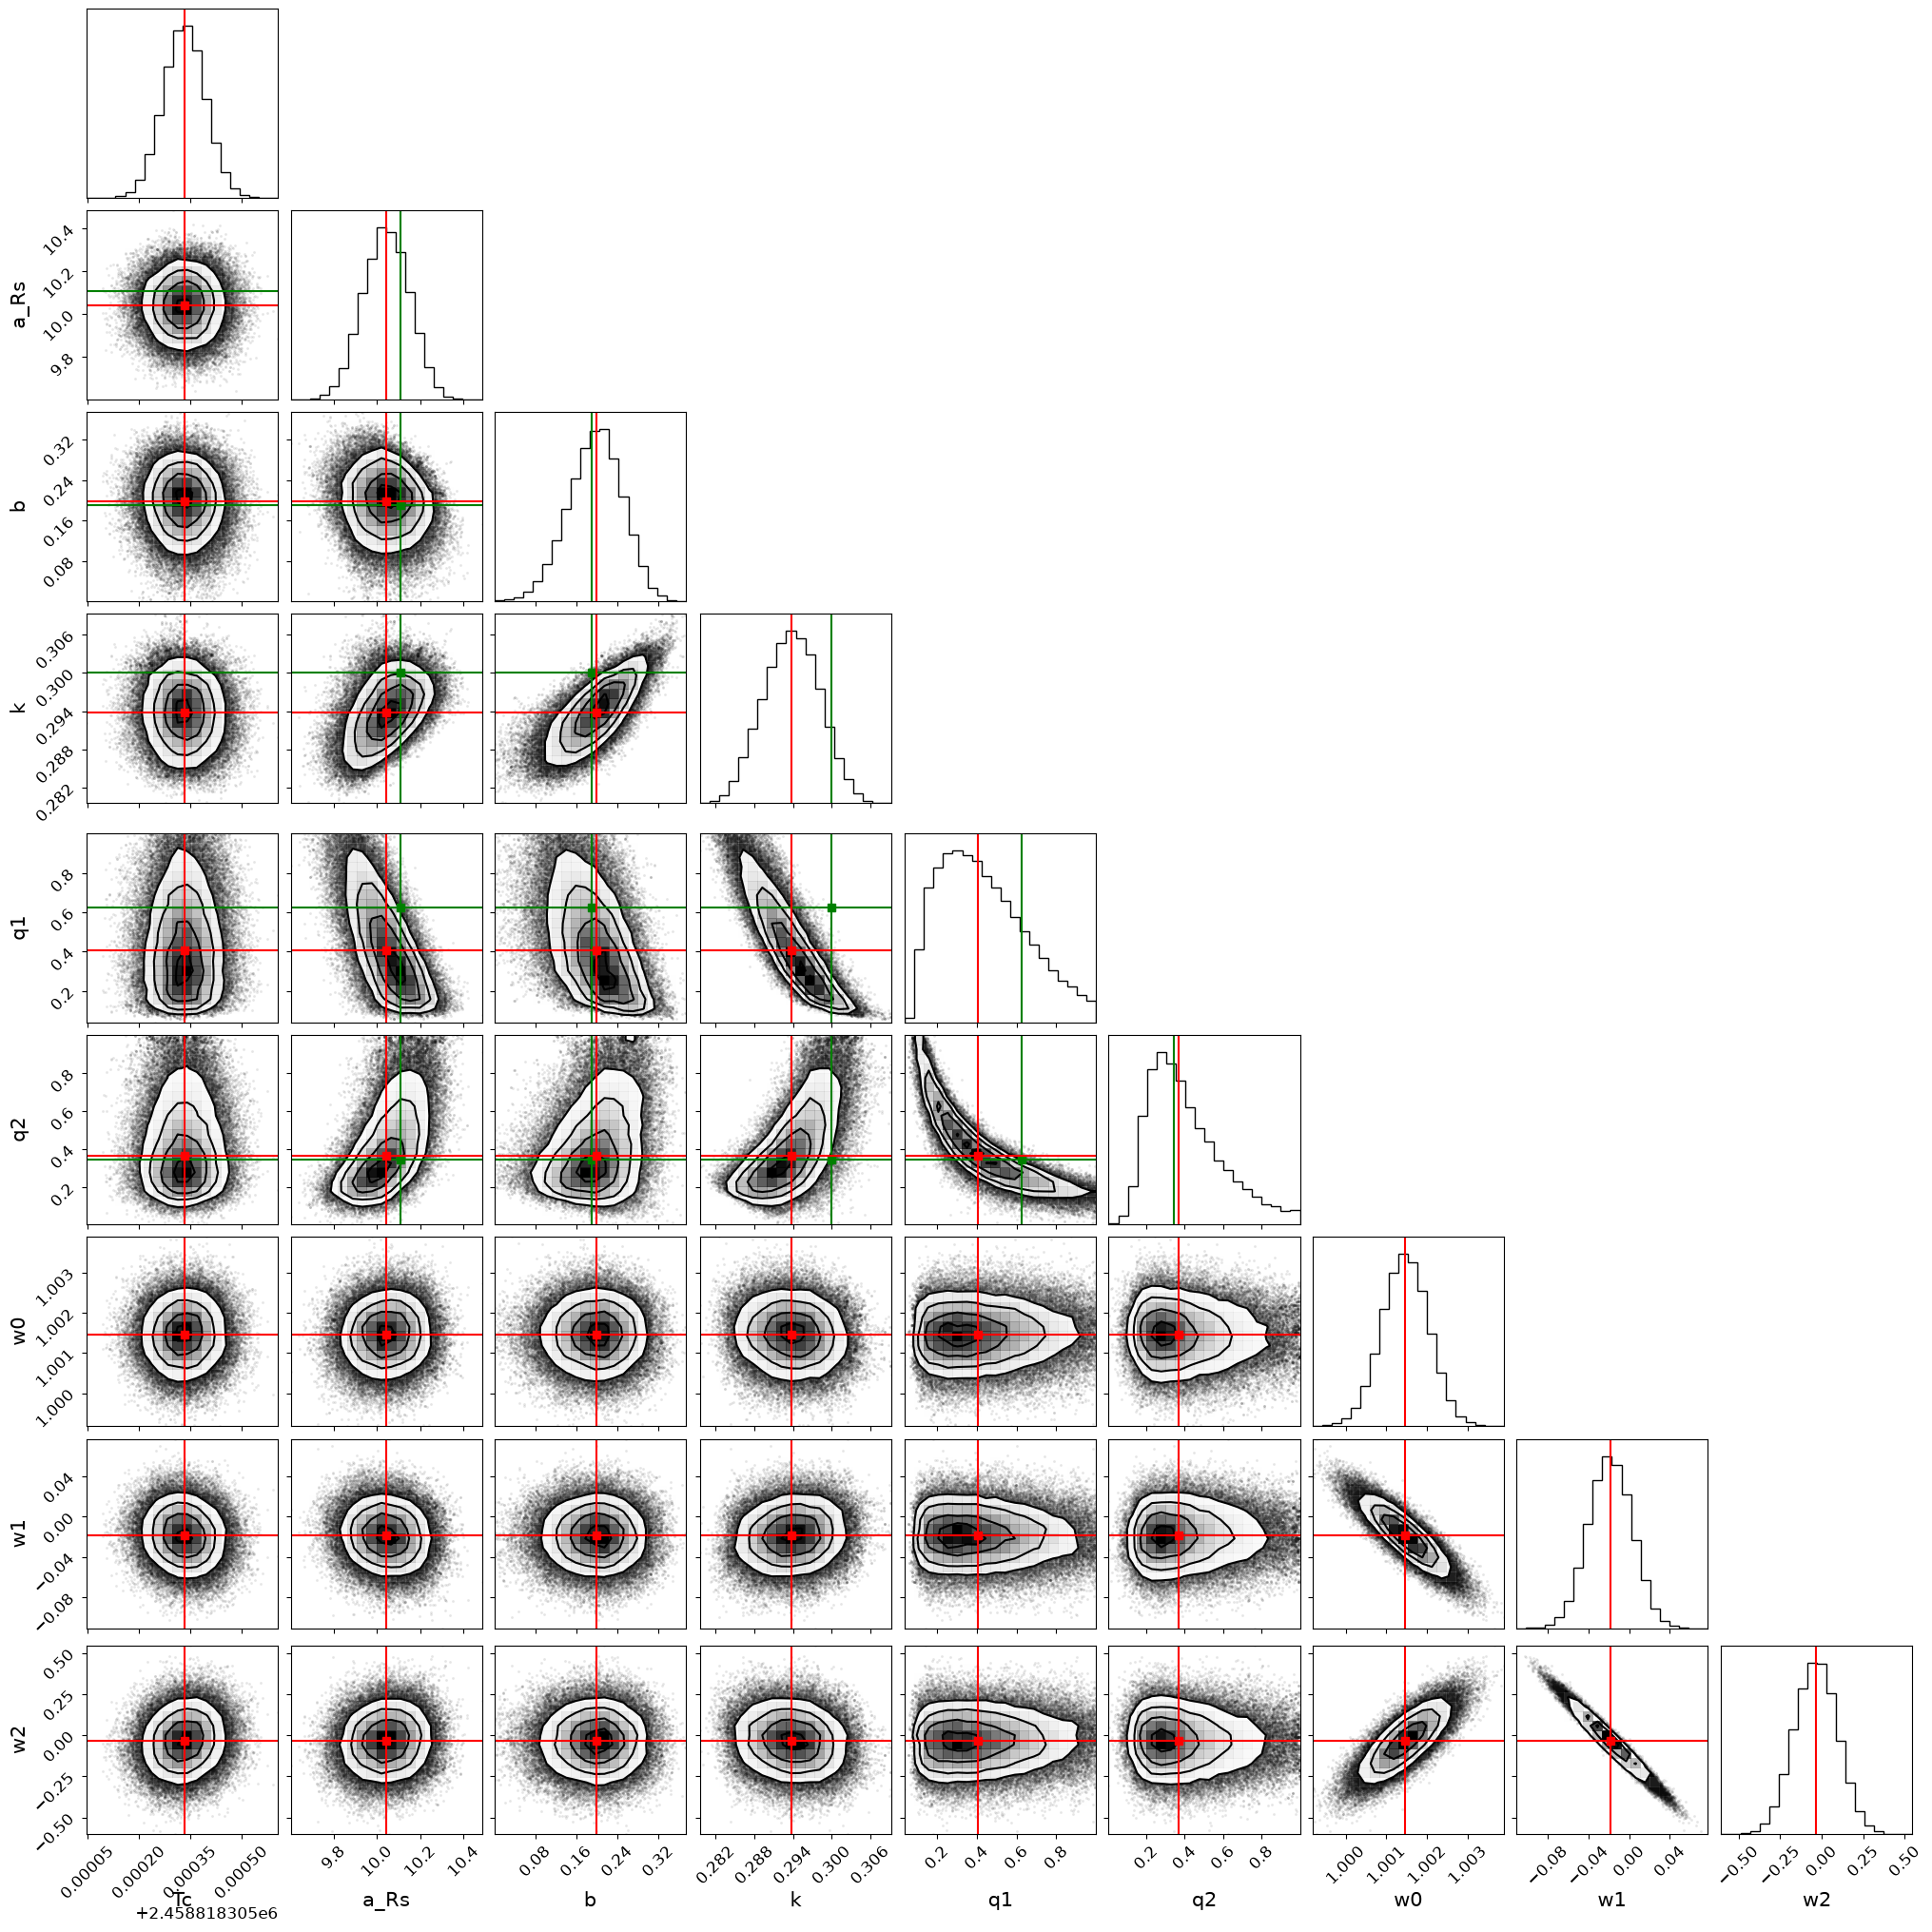

In [31]:
import corner

f = corner.corner(flat_samples, labels=params_name, label_kwargs=dict(fontsize=15))    
axes = np.array(f.axes).reshape((ndim, ndim))

# initial guess
for i in range(len_t):
    ax = axes[i, i]
    ax.axvline(transit_params_init[i], color="g")

for yi in range(len_t):
    for xi in range(yi):
        ax = axes[yi, xi]     
        ax.axvline(transit_params_init[xi], color="g")
        ax.axhline(transit_params_init[yi], color="g")
        ax.plot(transit_params_init[xi], transit_params_init[yi], "sg")

# best parameters
for i in range(ndim):
    ax = axes[i, i]
    ax.axvline(params_full_best[i], color="r")

for yi in range(ndim):
    for xi in range(yi):
        ax = axes[yi, xi]     
        ax.axvline(params_full_best[xi], color="r")
        ax.axhline(params_full_best[yi], color="r")
        ax.plot(params_full_best[xi], params_full_best[yi], "sr")

f.savefig(f'output/{target}_corner.pdf')

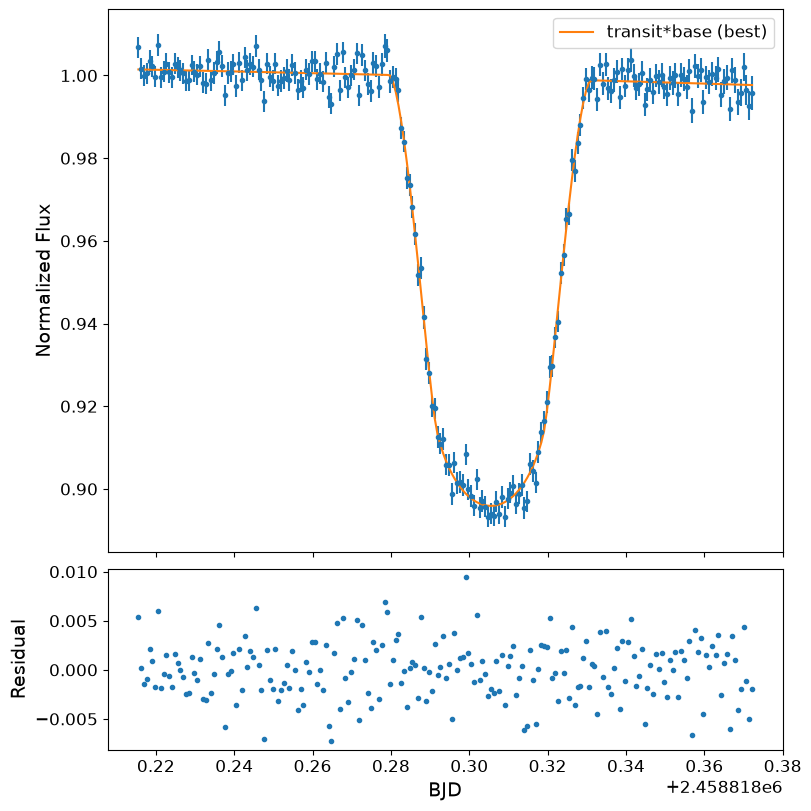

In [32]:
transit_params_best=params_full_best[:len_t]
base_params_best=params_full_best[len_t:]

transit_model_best=transit_model(transit_params_best, P_pr, time)
base_model_best = base_model(base_params_best,time)

plot_fit(time, flux, err, transit_model_best*base_model_best, 
         'transit*base (best)','transit_base_best')

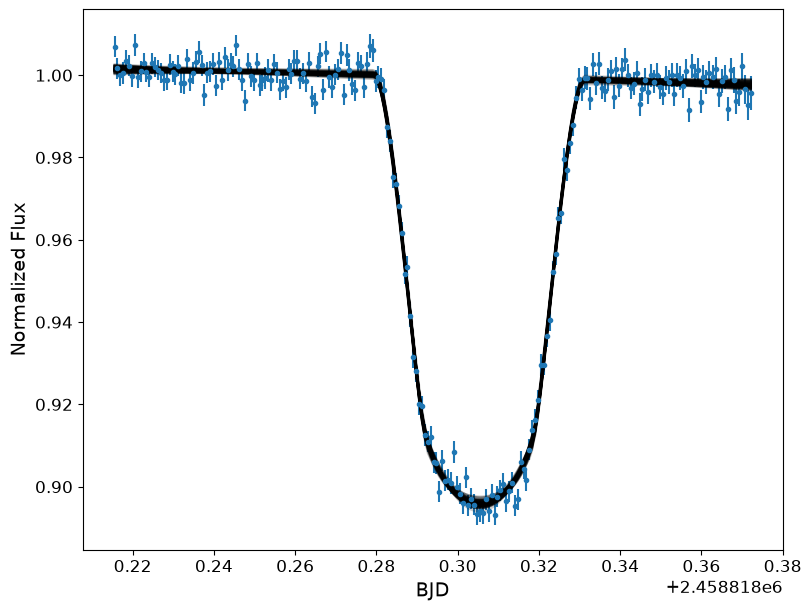

In [33]:
f = pl.figure(figsize=(8, 6))

pl.errorbar(time,flux,err, fmt='.', zorder=0)


for i in np.random.choice(np.arange(len(flat_samples)), 
                          size=100, replace=False):
    params_tmp = flat_samples[i]
    
    transit_params_tmp=params_tmp[:len_t]
    base_params_tmp=params_tmp[len_t:]

    transit_model_tmp=transit_model(transit_params_tmp, P_pr, time)
    base_model_tmp = base_model(base_params_tmp,time)
    
    pl.plot(time, transit_model_tmp * base_model_tmp, '-', 
            alpha=0.2, color='k', zorder=0)    

pl.xlabel('BJD')
pl.ylabel('Normalized Flux')

f.savefig(f'output/{target}_transit_base_100.pdf')

In [34]:
print("Parameter \t Initial  \t  Best  \t  Err")
print("----------------------------------------------")

for name, ini, best, err in zip(params_name[:6],
                                transit_params_init,
                                transit_params_best,
                                params_full_best_err[:6]):
    
    print(f"{name:8s} \t {ini:7.5f} \t {best:7.5f} \t {err:7.5f}")

Parameter 	 Initial  	  Best  	  Err
----------------------------------------------
Tc       	 2458818.30718 	 2458818.30533 	 0.00006
a_Rs     	 10.11000 	 10.04323 	 0.10709
b        	 0.19000 	 0.19897 	 0.05225
k        	 0.30000 	 0.29383 	 0.00437
q1       	 0.62663 	 0.40583 	 0.22693
q2       	 0.34370 	 0.36668 	 0.19063
